# 🎓 FEEDBACK PRIZE: Evaluating Student Writing
## 🤖 Token Classification & Discourse Argumentation Pipeline (DeBERTa-v3)
### ⚡ Google Colab (Tesla T4 GPU) & Local Environment Ready

---

### 📌 Խնդրի Նկարագրությունը (Problem Overview)
Այս նոթբուքում կառուցված է ամբողջական NLP փայփլայն՝ ուսանողական և աշակերտական էսսեներում արգումենտատիվ տարրերը (**Discourse Elements**) ավտոմատ հայտնաբերելու և դասակարգելու համար՝ օգտվելով իրական **Kaggle Feedback Prize** դատասեթից (`train.csv` և `train/*.txt`):

Էսսեի յուրաքանչյուր հատված (**Span**) դասակարգվում է հետևյալ **7 դասերից** որևէ մեկում․
1. **`Lead`** — Ներածություն, որը գրավում է ընթերցողի ուշադրությունը
2. **`Position`** — Հեղինակի հիմնական դիրքորոշումը կամ թեզը
3. **`Claim`** — Պնդում, որը պաշտպանում է դիրքորոշումը
4. **`Counterclaim`** — Հակափաստարկ, որը հերքում կամ կասկածի տակ է դնում դիրքորոշումը
5. **`Rebuttal`** — Հակափաստարկի հերքում
6. **`Evidence`** — Փաստացի ապացույց, օրինակ կամ վիճակագրություն
7. **`Concluding Statement`** — Եզրափակիչ եզրակացություն

---

### 🏗️ Փայփլայնի Ճարտարապետությունը (Pipeline Architecture)
```
 ┌────────────────────────────────────────────────────────┐
 │   1. Raw Kaggle Data (train.csv + train/*.txt)         │
 └──────────────────────────┬─────────────────────────────┘
                            ▼
 ┌────────────────────────────────────────────────────────┐
 │   2. Word-Level BIO Tagging (15 Labels)                │
 │      [O, B-Lead, I-Lead, B-Claim, I-Claim, ...]        │
 └──────────────────────────┬─────────────────────────────┘
                            ▼
 ┌────────────────────────────────────────────────────────┐
 │   3. Subword Token Alignment & Loss Masking (-100)     │
 │      DeBERTa-v3 Fast Tokenizer                         │
 └──────────────────────────┬─────────────────────────────┘
                            ▼
 ┌────────────────────────────────────────────────────────┐
 │   4. Transformer Deep Learning (DeBERTa-v3 Base)       │
 │      PyTorch AMP FP16 + GradScaler + AdamW + Scheduler │
 └──────────────────────────┬─────────────────────────────┘
                            ▼
 ┌────────────────────────────────────────────────────────┐
 │   5. Span-Level Post-Processing & Official Macro-F1    │
 │      IoU >= 0.5 Overlap Evaluation Metric              │
 └──────────────────────────┬─────────────────────────────┘
                            ▼
 ┌────────────────────────────────────────────────────────┐
 │   6. Interactive HTML Visualizer & Error Analysis      │
 │      Ground Truth vs Prediction Color Highlighting     │
 └────────────────────────────────────────────────────────┘
```

In [1]:
!pip install python-dotenv

## 0. 🔑 Dataset Download

In [1]:
import os
from pathlib import Path
import pandas as pd

# Project paths — data already exists in /content/data/raw from eda.ipynb
ROOT_DIR = Path("/content")
DATA_RAW_DIR = ROOT_DIR / "data" / "raw"
CSV_PATH = DATA_RAW_DIR / "train.csv"
TXT_DIR = DATA_RAW_DIR / "train"

if not CSV_PATH.exists() or not TXT_DIR.exists():
    raise FileNotFoundError(
        f"❌ Data not found in {DATA_RAW_DIR}\n"
        "Run notebooks/eda.ipynb first to download the dataset."
    )

df = pd.read_csv(CSV_PATH)
print(f"✅ Project root: {ROOT_DIR}")
print(f"✅ train.csv: {CSV_PATH}")
print(f"✅ train/ folder: {TXT_DIR}")
print(f"📊 Rows loaded: {len(df):,}")
print(f"📄 Unique essays: {df['id'].nunique():,}")

✅ Project root: /content
✅ train.csv: /content/data/raw/train.csv
✅ train/ folder: /content/data/raw/train
📊 Rows loaded: 144,293
📄 Unique essays: 15,594


## 1. 📦 Գրադարանների Տեղադրում և GPU Ստուգում (Tesla T4)

In [2]:
# Տեղադրում ենք անհրաժեշտ գրադարանները (Colab միջավայրի համար)
%pip install -q transformers sentencepiece protobuf datasets accelerate matplotlib seaborn

In [3]:
import os
import gc
import re
import random
import yaml
from pathlib import Path
from typing import List, Dict, Tuple, Any, Optional

# HF Hub xet-protocol-ի անջատում (կանխում է SentencePiece model-ի կախվելը Colab-ում)
os.environ['HUGGINGFACE_HUB_DISABLE_XET'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import LambdaLR
from sklearn.model_selection import train_test_split
from IPython.display import HTML, display

# Transformers մոդելներ և թոքենիզատորներ
from transformers import AutoTokenizer, AutoConfig, AutoModelForTokenClassification

# Լիարժեք Native PyTorch Linear Warmup Scheduler
def get_linear_schedule_with_warmup(optimizer, num_warmup_steps: int, num_training_steps: int, last_epoch: int = -1):
    def lr_lambda(current_step: int):
        if current_step < num_warmup_steps:
            return float(current_step) / float(max(1, num_warmup_steps))
        return max(0.0, float(num_training_steps - current_step) / float(max(1, num_training_steps - num_warmup_steps)))
    return LambdaLR(optimizer, lr_lambda, last_epoch)

# Ֆիքսենք պատահականության սերմը (Seed Reproducibility)
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(42)

# Ստուգենք հաշվողական սարքավորումը (Device Check)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"⚡ Հաշվարկներն իրականացվում են հետևյալ սարքի վրա՝ {device}")
if torch.cuda.is_available():
    print(f"   🚀 GPU Մոդել: {torch.cuda.get_device_name(0)}")
    print(f"   💾 Հասանելի VRAM: {round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2)} GB")
else:
    print("ℹ️ CUDA-ն հասանելի չէ, աշխատում է CPU-ով:")

⚡ Հաշվարկներն իրականացվում են հետևյալ սարքի վրա՝ cuda
   🚀 GPU Մոդել: Tesla T4
   💾 Հասանելի VRAM: 15.64 GB


In [4]:
CFG = {
    "model_name": "microsoft/deberta-v3-base",
    "max_len": 1024,
    "num_labels": 15,
    "dropout": 0.1,
    "seed": 42,
    "epochs": 2,
    "batch_size": 2,
    "gradient_accumulation_steps": 8,
    "learning_rate": 3.0e-5,
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,
    "max_grad_norm": 1.0,
    "o_class_weight": 0.30,
    "o_threshold": 0.35,
    "max_train_essays": None,
    "output_dir": "outputs/"
}

os.makedirs(CFG["output_dir"], exist_ok=True)

DISCOURSE_TYPES = [
    "Lead", "Position", "Claim", "Counterclaim",
    "Rebuttal", "Evidence", "Concluding Statement"
]

LABELS = ["O"]
for dt in DISCOURSE_TYPES:
    LABELS.append(f"B-{dt}")
    LABELS.append(f"I-{dt}")

LABEL2ID = {lbl: i for i, lbl in enumerate(LABELS)}
ID2LABEL = {i: lbl for i, lbl in enumerate(LABELS)}
NUM_LABELS = len(LABELS)

print(f"🏷️ Total BIO labels: {NUM_LABELS}")

🏷️ Total BIO labels: 15


## 2. 🏷️ BIO Պիտակավորում և Subword Alignment (Data Preprocessing)

> 🔍 **Մեխանիզմը**․
> 1. Էսսեի տեքստը բաժանվում է բառերի (`words = text.split()`):
> 2. `train.csv`-ի `predictionstring`-ի միջոցով յուրաքանչյուր բառին տրվում է `B-{type}`, `I-{type}` կամ `O` պիտակ:
> 3. Fast Tokenizer-ը բառը տրոհում է sub-word-ների․ առաջին sub-word-ը ստանում է իրական լեյբլը, իսկ հաջորդ sub-word-ներն ու հատուկ թոքենները (`[CLS]`, `[SEP]`, `[PAD]`) ստանում են **`-100`** (որպեսզի CrossEntropyLoss-ը դրանք անտեսի):

In [5]:
def get_essay_text(essay_id: str, txt_dir: Path) -> str:
    path = os.path.join(str(txt_dir), f"{essay_id}.txt")
    with open(path, "r", encoding="utf-8") as f:
        return f.read()

def build_word_labels(essay_id: str, text: str, grouped_df: dict) -> Tuple[List[str], List[str]]:
    words = text.split()
    word_labels = ["O"] * len(words)

    if essay_id in grouped_df:
        essay_rows = grouped_df[essay_id]
        for _, row in essay_rows.iterrows():
            dtype = row["discourse_type"]
            w_indices = [int(x) for x in str(row["predictionstring"]).split()]
            if not w_indices:
                continue

            if w_indices[0] < len(word_labels):
                word_labels[w_indices[0]] = f"B-{dtype}"

            for idx in w_indices[1:]:
                if idx < len(word_labels):
                    word_labels[idx] = f"I-{dtype}"

    return words, word_labels

# Ցուցադրական թեստ իրական դատասեթի առաջին էսսեի վրա
grouped_df = dict(tuple(df.groupby('id')))
sample_id = df['id'].iloc[0]
sample_text = get_essay_text(sample_id, TXT_DIR)
words, w_labels = build_word_labels(sample_id, sample_text, grouped_df)

print(f"Էսսե ID: {sample_id}")
print(f"Բառերի ընդհանուր քանակ: {len(words)}")
print("Առաջին 15 բառերն ու նրանց BIO պիտակները:")
for w, l in zip(words[:15], w_labels[:15]):
    print(f"  {w:<20} ➔ {l}")

Էսսե ID: 423A1CA112E2
Բառերի ընդհանուր քանակ: 379
Առաջին 15 բառերն ու նրանց BIO պիտակները:
  Phones               ➔ O
  Modern               ➔ B-Lead
  humans               ➔ I-Lead
  today                ➔ I-Lead
  are                  ➔ I-Lead
  always               ➔ I-Lead
  on                   ➔ I-Lead
  their                ➔ I-Lead
  phone.               ➔ I-Lead
  They                 ➔ I-Lead
  are                  ➔ I-Lead
  always               ➔ I-Lead
  on                   ➔ I-Lead
  their                ➔ I-Lead
  phone                ➔ I-Lead


## 3. 📦 PyTorch Dataset & Train/Validation DataLoaders

In [6]:
class FeedbackDataset(Dataset):
    def __init__(self, essay_ids: List[str], df: pd.DataFrame, tokenizer, txt_dir: Path, max_len: int = 512):
        self.essay_ids = essay_ids
        self.tokenizer = tokenizer
        self.txt_dir = str(txt_dir)
        self.max_len = max_len
        self.grouped_df = dict(tuple(df[df['id'].isin(set(essay_ids))].groupby('id')))

    def __len__(self) -> int:
        return len(self.essay_ids)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        essay_id = self.essay_ids[idx]
        text = get_essay_text(essay_id, self.txt_dir)
        words, word_labels = build_word_labels(essay_id, text, self.grouped_df)

        encoding = self.tokenizer(
            words,
            is_split_into_words=True,
            truncation=True,
            max_length=self.max_len,
            padding="max_length",
            return_tensors=None
        )

        word_ids = encoding.word_ids()
        aligned_labels = []
        prev_word_id = None

        for w_id in word_ids:
            if w_id is None:
                aligned_labels.append(-100)
            elif w_id != prev_word_id:
                label_name = word_labels[w_id] if w_id < len(word_labels) else "O"
                aligned_labels.append(LABEL2ID[label_name])
            else:
                aligned_labels.append(-100)
            prev_word_id = w_id

        return {
            "input_ids": torch.tensor(encoding["input_ids"], dtype=torch.long),
            "attention_mask": torch.tensor(encoding["attention_mask"], dtype=torch.long),
            "labels": torch.tensor(aligned_labels, dtype=torch.long)
        }

# Բաժանում Train (85%) և Validation (15%) բազմությունների
all_essay_ids = df["id"].unique().tolist()
train_ids, val_ids = train_test_split(all_essay_ids, test_size=0.15, random_state=CFG["seed"])

tokenizer = AutoTokenizer.from_pretrained(CFG["model_name"], use_fast=True)

train_ds = FeedbackDataset(train_ids, df, tokenizer, TXT_DIR, max_len=CFG["max_len"])
val_ds = FeedbackDataset(val_ids, df, tokenizer, TXT_DIR, max_len=CFG["max_len"])

batch_size = CFG["batch_size"]
num_workers = 2 if os.name != 'nt' else 0
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=True, num_workers=num_workers, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=torch.cuda.is_available())

print(f"📊 Տվյալների բաշխումը՝")
print(f"   • Train էսսեներ: {len(train_ids):,} ({len(train_loader):,} batches)")
print(f"   • Val   էսսեներ: {len(val_ids):,} ({len(val_loader):,} batches)")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

📊 Տվյալների բաշխումը՝
   • Train էսսեներ: 13,254 (6,627 batches)
   • Val   էսսեներ: 2,340 (1,170 batches)


## 4. 🧠 Մոդելի Ճարտարապետություն (DeBERTa-v3 Token Classifier)

Մոդելի հիմքը `microsoft/deberta-v3-base` տրանսֆորմերն է։ Բոլոր պարամետրերը ֆիքսված են **FP32**-ով՝ PyTorch AMP Mixed Precision-ի հետ անխափան աշխատանքի համար։

In [7]:
class FeedbackModel(nn.Module):
    def __init__(self, model_name: str, num_labels: int, dropout: float = 0.2):
        super().__init__()
        self.config = AutoConfig.from_pretrained(model_name)
        self.config.num_labels = num_labels
        self.config.hidden_dropout_prob = dropout
        self.config.attention_probs_dropout_prob = dropout

        # Բեռնում ենք pretrained մոդելը explicitly FP32-ով (կանխում է unscale FP16 error-ը)
        self.model = AutoModelForTokenClassification.from_pretrained(
            model_name,
            config=self.config,
            torch_dtype=torch.float32
        )
        self.model.float()

    def forward(self, input_ids, attention_mask, labels=None):
        return self.model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels,
            return_dict=True
        )

print(f"✅ Մոդելը սահմանված է `{CFG['model_name']}`-ի հիման վրա (15 BIO ելքային դասերով):")

✅ Մոդելը սահմանված է `microsoft/deberta-v3-base`-ի հիման վրա (15 BIO ելքային դասերով):


## 5. 🎯 Գնահատման Պաշտոնական Մետրիկա (Span Overlap IoU $\ge 0.5$ Macro-F1)

In [8]:
def compute_overlap_ratio(pred_span: Tuple[int, int], true_span: Tuple[int, int]) -> float:
    """
    Հաշվարկում է երկու սպանների Intersection over Union (IoU) հարաբերակցությունը:
    """
    p_start, p_end = pred_span
    t_start, t_end = true_span
    intersection = max(0, min(p_end, t_end) - max(p_start, t_start) + 1)
    union = max(p_end, t_end) - min(p_start, t_start) + 1
    return intersection / union if union > 0 else 0.0

def score_feedback_comp(pred_df: pd.DataFrame, gt_df: pd.DataFrame, overlap_threshold: float = 0.5) -> float:
    """
    Kaggle Feedback Prize պաշտոնական Macro-F1 մետրիկայի հաշվարկ:
    """
    macro_f1, _ = score_feedback_comp_detailed(pred_df, gt_df, overlap_threshold=overlap_threshold)
    return macro_f1

def score_feedback_comp_detailed(pred_df: pd.DataFrame, gt_df: pd.DataFrame, overlap_threshold: float = 0.5) -> Tuple[float, pd.DataFrame]:
    """
    Kaggle Feedback Prize պաշտոնական Macro-F1 մետրիկայի և դասերի մանրամասն (Precision, Recall, F1) հաշվարկ:
    """
    class_metrics = []
    f1_scores = []
    for discourse_type in DISCOURSE_TYPES:
        pred_type_df = pred_df[pred_df['discourse_type'] == discourse_type] if not pred_df.empty and 'discourse_type' in pred_df else pd.DataFrame()
        gt_type_df = gt_df[gt_df['discourse_type'] == discourse_type] if not gt_df.empty and 'discourse_type' in gt_df else pd.DataFrame()

        pred_grouped = pred_type_df.groupby('id') if not pred_type_df.empty else None
        gt_grouped = gt_type_df.groupby('id') if not gt_type_df.empty else None

        all_essay_ids = set()
        if not gt_df.empty and 'id' in gt_df:
            all_essay_ids.update(gt_df['id'].unique())
        if not pred_df.empty and 'id' in pred_df:
            all_essay_ids.update(pred_df['id'].unique())

        tp, fp, fn = 0, 0, 0
        gt_total = len(gt_type_df)
        pred_total = len(pred_type_df)

        for essay_id in all_essay_ids:
            preds = pred_grouped.get_group(essay_id) if (pred_grouped is not None and essay_id in pred_grouped.groups) else pd.DataFrame()
            gts = gt_grouped.get_group(essay_id) if (gt_grouped is not None and essay_id in gt_grouped.groups) else pd.DataFrame()

            pred_spans = [(int(str(ps).split()[0]), int(str(ps).split()[-1])) for ps in preds['predictionstring'].values if len(str(ps).split()) > 0] if not preds.empty and 'predictionstring' in preds else []
            gt_spans = [(int(str(ps).split()[0]), int(str(ps).split()[-1])) for ps in gts['predictionstring'].values if len(str(ps).split()) > 0] if not gts.empty and 'predictionstring' in gts else []

            matched_gt = set()
            for p_span in pred_spans:
                best_iou = 0.0
                best_gt_idx = -1
                for idx, g_span in enumerate(gt_spans):
                    if idx in matched_gt:
                        continue
                    iou = compute_overlap_ratio(p_span, g_span)
                    if iou > best_iou:
                        best_iou = iou
                        best_gt_idx = idx
                if best_iou >= overlap_threshold:
                    tp += 1
                    matched_gt.add(best_gt_idx)
                else:
                    fp += 1
            fn += len(gt_spans) - len(matched_gt)

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
        f1_scores.append(f1)

        class_metrics.append({
            "Discourse Type": discourse_type,
            "Precision": round(precision, 4),
            "Recall": round(recall, 4),
            "F1-Score": round(f1, 4),
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Ground Truth Count": gt_total,
            "Pred Count": pred_total
        })

    macro_f1 = float(np.mean(f1_scores)) if f1_scores else 0.0
    detailed_df = pd.DataFrame(class_metrics)
    return macro_f1, detailed_df

print("✅ Պաշտոնական Macro-F1 մետրիկայի ֆունկցիաները (score_feedback_comp & score_feedback_comp_detailed) պատրաստ են:")


✅ Պաշտոնական Macro-F1 մետրիկայի ֆունկցիաները (score_feedback_comp & score_feedback_comp_detailed) պատրաստ են:


## 6. 🚀 Ուսուցման Ցիկլ և Վալիդացիա (Tesla T4 GPU Autocast / Mixed Precision)

Օգտագործում ենք PyTorch AMP `autocast` + `GradScaler`՝ անվտանգ unscaling-ով և կշռված CrossEntropy կորստի ֆունկցիայով։

In [ ]:
# Մաքրենք GPU-ի հիշողությունը
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Կշռված Loss ֆունկցիա՝ 'O' (Outside) դասի downweight-ով (0.30)
o_weight = float(CFG["o_class_weight"])
class_weights = torch.ones(NUM_LABELS, dtype=torch.float32, device=device)
class_weights[0] = o_weight
loss_fn = nn.CrossEntropyLoss(weight=class_weights, ignore_index=-100)

use_cuda = torch.cuda.is_available()
scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)

def train_epoch(model, loader, optimizer, scheduler, scaler, device, max_grad_norm: float = 1.0, grad_accum_steps: int = 2):
    model.train()
    total_loss = 0.0
    optimizer.zero_grad()

    pbar = tqdm(loader, desc="Training Batch", leave=False)
    for step, batch in enumerate(pbar):
        input_ids = batch["input_ids"].to(device, non_blocking=True)
        attention_mask = batch["attention_mask"].to(device, non_blocking=True)
        labels = batch["labels"].to(device, non_blocking=True)

        with torch.amp.autocast(device_type="cuda" if use_cuda else "cpu", enabled=use_cuda):
            outputs = model(input_ids, attention_mask)
            logits = outputs.logits  # [batch_size, seq_len, num_labels]
            loss = loss_fn(logits.view(-1, NUM_LABELS).float(), labels.view(-1))
            loss = loss / grad_accum_steps

        if use_cuda:
            scaler.scale(loss).backward()
        else:
            loss.backward()

        total_loss += loss.item() * grad_accum_steps

        if (step + 1) % grad_accum_steps == 0 or (step + 1) == len(loader):
            if use_cuda:
                try:
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
                    scaler.step(optimizer)
                    scaler.update()
                except ValueError:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
                    scaler.step(optimizer)
                    scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
                optimizer.step()

            optimizer.zero_grad()
            scheduler.step()

        pbar.set_postfix({"loss": f"{loss.item() * grad_accum_steps:.4f}"})

    return total_loss / max(1, len(loader))

def evaluate(model, loader, device):
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch in tqdm(loader, desc="Validation", leave=False):
            input_ids = batch["input_ids"].to(device, non_blocking=True)
            attention_mask = batch["attention_mask"].to(device, non_blocking=True)
            labels = batch["labels"].to(device, non_blocking=True)

            with torch.amp.autocast(device_type="cuda" if use_cuda else "cpu", enabled=use_cuda):
                outputs = model(input_ids, attention_mask)
                logits = outputs.logits
                loss = loss_fn(logits.view(-1, NUM_LABELS).float(), labels.view(-1))
            val_loss += loss.item()

    return val_loss / max(1, len(loader))

# Ինիցիալիզացնում ենք մոդելը
model = FeedbackModel(CFG["model_name"], NUM_LABELS, dropout=CFG["dropout"]).to(device)
model.float()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=float(CFG["learning_rate"]),
    eps=1e-6,
    weight_decay=float(CFG["weight_decay"])
)

epochs = CFG["epochs"]
grad_accum = CFG["gradient_accumulation_steps"]
total_steps = (len(train_loader) // grad_accum) * epochs
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * CFG["warmup_ratio"]),
    num_training_steps=max(1, total_steps)
)

print(f"=== 🚀 ՍԿՍՎՈՒՄ Է ՈՒՍՈՒՑՈՒՄԸ ({epochs} ԷՊՈԽ) ===")
best_val_loss = float("inf")
checkpoint_path = os.path.join(CFG["output_dir"], "model_weights.pt")

history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(epochs):
    train_loss = train_epoch(model, train_loader, optimizer, scheduler, scaler, device, max_grad_norm=CFG["max_grad_norm"], grad_accum_steps=grad_accum)
    val_loss = evaluate(model, val_loader, device)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(f"  Էպոխ {epoch + 1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), checkpoint_path)
        print(f"  ⭐ Լավագույն մոդելը պահպանվեց՝ {checkpoint_path}")

print(f"\n✅ Ուսուցումն ավարտված է: Լավագույն Val Loss: {best_val_loss:.4f}")

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForTokenClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
classifier.bias                         | MISSING    | 
classifier.weight                       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task

=== 🚀 ՍԿՍՎՈՒՄ Է ՈՒՍՈՒՑՈՒՄԸ (2 ԷՊՈԽ) ===


Training Batch:   0%|          | 0/6627 [00:00<?, ?it/s]

/tmp/ipykernel_5743/236683399.py:55: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


## 7. 📈 Ուսուցման Դինամիկա և Գրաֆիկներ (Training Visualizations)

Գծապատկերում ենք Training Loss vs Validation Loss կորերը ըստ էպոխների։

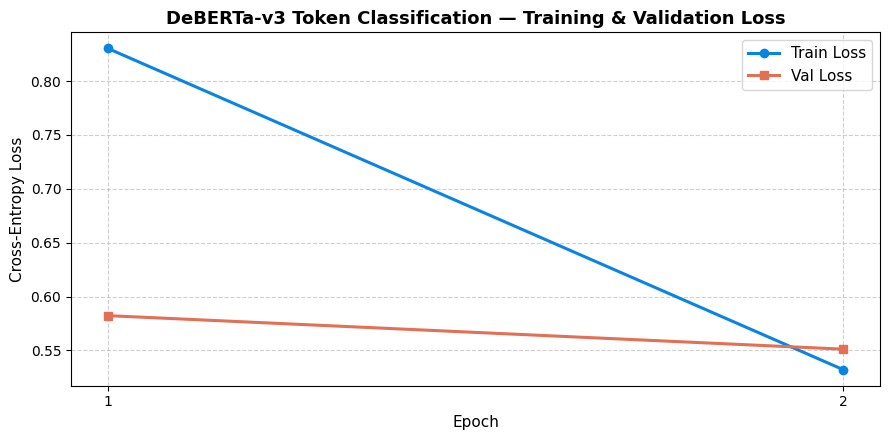

✅ Գրաֆիկը պահպանվեց՝ outputs/loss_curve.png


In [ ]:
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], marker='o', color='#0984e3', linewidth=2.2, label='Train Loss')
plt.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"], marker='s', color='#e17055', linewidth=2.2, label='Val Loss')
plt.title("DeBERTa-v3 Token Classification — Training & Validation Loss", fontsize=13, fontweight='bold')
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Cross-Entropy Loss", fontsize=11)
plt.xticks(range(1, len(history["train_loss"]) + 1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(CFG["output_dir"], "loss_curve.png"), dpi=200)
plt.show()
print(f"✅ Գրաֆիկը պահպանվեց՝ {CFG['output_dir']}loss_curve.png")

## 8. 🔮 Ինֆերենս և Դիսկուրսիվ Սպանների Դուրսբերում (Inference & Post-Processing)

Կանխատեսված sub-word թոքենները միավորվում են բառերի, իսկ BIO պիտակները վերածվում են ամբողջական դիսկուրսիվ հատվածների (Spans): Կիրառվում է նաև հետամշակում (նվազագույն երկարության զտում աղմուկը վերացնելու համար)։

In [ ]:
def predict_essay_spans(
    text: str,
    model: nn.Module,
    tokenizer,
    device: torch.device,
    max_len: int = 512,
    o_threshold: float = 0.50,
    min_len_dict: Optional[Dict[str, int]] = None
) -> List[Dict[str, Any]]:
    """
    Ընդունում է հում տեքստ և վերադարձնում դիսկուրսիվ սպանների ցուցակ՝
    իրենց դասով, բառերի ինդեքսներով և վստահության մակարդակով (Confidence):
    """
    if min_len_dict is None:
        min_len_dict = {
            "Lead": 3, "Position": 2, "Claim": 2,
            "Counterclaim": 2, "Rebuttal": 2,
            "Evidence": 5, "Concluding Statement": 4
        }

    words = text.split()
    if not words:
        return []

    tokenized = tokenizer(
        words,
        is_split_into_words=True,
        truncation=True,
        max_length=max_len,
        padding="max_length",
        return_tensors="pt"
    )

    word_ids = tokenized.word_ids()
    input_ids = tokenized["input_ids"].to(device)
    attention_mask = tokenized["attention_mask"].to(device)

    model.eval()
    with torch.no_grad():
        with torch.amp.autocast(device_type="cuda" if device.type == "cuda" else "cpu", enabled=device.type == "cuda"):
            outputs = model(input_ids, attention_mask)
            logits = outputs.logits[0]  # [seq_len, num_labels]
            probs = torch.softmax(logits.float(), dim=-1).cpu().numpy()

    # Subword -> Word mapping
    word_pred_labels = ["O"] * len(words)
    word_confs = [1.0] * len(words)
    seen_words = set()

    for token_idx, w_id in enumerate(word_ids):
        if w_id is None or w_id in seen_words:
            continue
        if w_id < len(words):
            p = probs[token_idx]
            if p[0] < o_threshold:
                best_idx = int(np.argmax(p[1:])) + 1
            else:
                best_idx = int(np.argmax(p))
            word_pred_labels[w_id] = ID2LABEL[best_idx]
            word_confs[w_id] = float(p[best_idx])
        seen_words.add(w_id)

    # Group BIO -> Spans
    spans = []
    current_type = None
    current_start = None
    current_confs = []

    def add_span(ctype, cstart, cend, conf_list):
        span_len = cend - cstart + 1
        if span_len >= min_len_dict.get(ctype, 1):
            span_text = " ".join(words[cstart:cend+1])
            mean_conf = float(np.mean(conf_list)) if conf_list else 1.0
            spans.append({
                "type": ctype,
                "start_word": cstart,
                "end_word": cend,
                "text": span_text,
                "confidence": mean_conf,
                "predictionstring": " ".join(str(x) for x in range(cstart, cend + 1))
            })

    for i, (lbl, conf) in enumerate(zip(word_pred_labels, word_confs)):
        if lbl.startswith("B-"):
            if current_type is not None:
                add_span(current_type, current_start, i - 1, current_confs)
            current_type = lbl[2:]
            current_start = i
            current_confs = [conf]
        elif lbl.startswith("I-"):
            tag_type = lbl[2:]
            if current_type == tag_type:
                current_confs.append(conf)
            else:
                if current_type is not None:
                    add_span(current_type, current_start, i - 1, current_confs)
                current_type = tag_type
                current_start = i
                current_confs = [conf]
        else: # "O"
            if current_type is not None:
                add_span(current_type, current_start, i - 1, current_confs)
            current_type = None
            current_start = None
            current_confs = []

    if current_type is not None:
        add_span(current_type, current_start, len(words) - 1, current_confs)

    return spans

# Բեռնենք լավագույն պահպանված քաշերը
if os.path.exists(checkpoint_path):
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    print(f"⭐ Բեռնվեցին լավագույն քաշերը՝ {checkpoint_path}")

# Փորձարկենք Validation բազմության իրական էսսեի վրա
test_eid = val_ids[0]
test_essay = get_essay_text(test_eid, TXT_DIR)

predicted_spans = predict_essay_spans(
    test_essay,
    model,
    tokenizer,
    device,
    max_len=CFG["max_len"],
    o_threshold=float(CFG["o_threshold"])
)

print(f"\n=== 🎯 ԿԱՆԽԱՏԵՍՎԱԾ ԴԻՍԿՈՒՐՍԻՎ ՍՊԱՆՆԵՐԸ (Էսսե: {test_eid}, {len(predicted_spans)} սպան) ===\n")
for sp in predicted_spans:
    short_txt = (sp["text"][:70] + "...") if len(sp["text"]) > 70 else sp["text"]
    conf_pct = sp["confidence"] * 100
    print(f"🏷️ [{sp['type']:<20}] (Բառեր {sp['start_word']:>3}-{sp['end_word']:>3} | Conf: {conf_pct:>5.1f}%): \"{short_txt}\"")

⭐ Բեռնվեցին լավագույն քաշերը՝ outputs/model_weights.pt

=== 🎯 ԿԱՆԽԱՏԵՍՎԱԾ ԴԻՍԿՈՒՐՍԻՎ ՍՊԱՆՆԵՐԸ (Էսսե: E805EA83734A, 11 սպան) ===

🏷️ [Lead                ] (Բառեր   3- 34 | Conf:  80.1%): "The electoral collage system has worked for many years however, citize..."
🏷️ [Claim               ] (Բառեր  35- 39 | Conf:  64.3%): "It is unfair to voters,"
🏷️ [Claim               ] (Բառեր  42- 51 | Conf:  55.2%): "the disaster factor is a perfect example going against it."
🏷️ [Position            ] (Բառեր  52- 73 | Conf:  86.4%): "Popular vote should be used in our modern society for a fair and clean..."
🏷️ [Claim               ] (Բառեր  74- 94 | Conf:  76.0%): "The electoral collage voting system is an uncanny way for citizens to ..."
🏷️ [Evidence            ] (Բառեր  95-141 | Conf:  85.9%): "They are voting for electors, not actual canidates. It isn't a straigh..."
🏷️ [Evidence            ] (Բառեր 143-151 | Conf:  52.2%): "a cheat to people who live in our country."
🏷️ [Evidence            ] (Բա

## 9. 🎨 Ինտերակտիվ HTML Գունավոր Վիզուալիզատոր (Interactive Highlighter)

Համեմատում ենք էսսեի իրական նշագրված սպանները (**Ground Truth**) մոդելի կանխատեսած սպանների (**Model Predictions**) հետ՝ ինտերակտիվ գունավոր HTML վիզուալիզացիայով։

In [ ]:
# Յուրաքանչյուր դասի գունային պալիտրան (Color Palette)
COLORS = {
    "Lead": "#ffeaa7",                 # Դեղնավուն
    "Position": "#55efc4",             # Բաց Կանաչ
    "Claim": "#81ecec",                # Փիրուզագույն
    "Counterclaim": "#fab1a0",         # Նարնջագույն
    "Rebuttal": "#ff7675",             # Վարդագույն
    "Evidence": "#74b9ff",             # Կապույտ
    "Concluding Statement": "#a29bfe"  # Մանուշակագույն
}

def render_discourse_html(text: str, spans: List[Dict[str, Any]], title: str = "Դիսկուրսիվ Էլեմենտների Վիզուալիզացիա") -> str:
    words = text.split()
    word_meta = [None] * len(words)

    for sp in spans:
        dtype = sp["type"]
        s_idx = sp["start_word"]
        e_idx = sp["end_word"]
        for i in range(s_idx, min(e_idx + 1, len(words))):
            word_meta[i] = dtype

    # 1. Գույների լեգենդ (Color Legend)
    legend_items = []
    for dt, col in COLORS.items():
        legend_items.append(
            f"<span style='background-color: {col}; color: #2d3436; padding: 4px 9px; margin: 3px; border-radius: 6px; font-weight: bold; font-size: 12px; display: inline-block; box-shadow: 0 1px 3px rgba(0,0,0,0.1);'>{dt}</span>"
        )
    legend_html = "".join(legend_items)

    # 2. Տեքստի ներկումը
    html_chunks = [
        f"<div style='border: 2px solid #dfe6e9; border-radius: 12px; padding: 20px; background: #ffffff; margin-top: 10px; font-family: Segoe UI, sans-serif;'>",
        f"<h3 style='margin-top: 0; color: #2d3436; font-size: 18px;'>📊 {title}</h3>",
        f"<div style='margin-bottom: 18px; padding-bottom: 12px; border-bottom: 1px solid #edf2f7;'>{legend_html}</div>",
        "<div style='line-height: 2.5; font-size: 16px; color: #2d3436;'>"
    ]

    cur_type = None
    for w, dt in zip(words, word_meta):
        if dt != cur_type:
            if cur_type is not None:
                html_chunks.append(f" <b style='font-size: 11px; color: #2d3436; background: rgba(255,255,255,0.85); padding: 2px 6px; border-radius: 4px; border: 1px solid rgba(0,0,0,0.1);'>[{cur_type}]</b></span> ")
            if dt is not None:
                color = COLORS.get(dt, "#dfe6e9")
                html_chunks.append(f"<span style='background-color: {color}; padding: 4px 8px; border-radius: 6px; margin: 0 2px; box-shadow: 0 1px 2px rgba(0,0,0,0.08);'>")
            cur_type = dt
        html_chunks.append(w + " ")

    if cur_type is not None:
        html_chunks.append(f" <b style='font-size: 11px; color: #2d3436; background: rgba(255,255,255,0.85); padding: 2px 6px; border-radius: 4px; border: 1px solid rgba(0,0,0,0.1);'>[{cur_type}]</b></span>")

    html_chunks.append("</div></div>")
    return "".join(html_chunks)

# Ցուցադրում 1: Իրական նշագրված սպանները (Ground Truth)
sample_eid = val_ids[0]
sample_txt = get_essay_text(sample_eid, TXT_DIR)
gt_rows = df[df['id'] == sample_eid]
gt_spans_list = []
for _, row in gt_rows.iterrows():
    dtype = row["discourse_type"]
    w_idxs = [int(x) for x in str(row["predictionstring"]).split()]
    if w_idxs:
        span_txt = " ".join(sample_txt.split()[w_idxs[0]:w_idxs[-1]+1])
        gt_spans_list.append({
            "type": dtype,
            "start_word": w_idxs[0],
            "end_word": w_idxs[-1],
            "text": span_txt,
            "confidence": 1.0,
            "predictionstring": str(row["predictionstring"])
        })

gt_view = render_discourse_html(sample_txt, gt_spans_list, title=f"Իրական Էսսեի Ճիշտ Պիտակները (Ground Truth: {sample_eid})")
display(HTML(gt_view))

# Ցուցադրում 2: Մոդելի կանխատեսած սպանները (Model Predictions)
pred_view = render_discourse_html(sample_txt, predicted_spans, title=f"Մոդելի Կանխատեսած Սպանները (Predicted: {sample_eid})")
display(HTML(pred_view))

## 10. 🎯 Պաշտոնական Մետրիկայի Հաշվարկ (Validation Span Overlap Macro-F1 Evaluation)

Կիրառում ենք Kaggle Feedback Prize պաշտոնական **Span-Level Overlap (IoU $\ge 0.5$) Macro-F1** մետրիկան վալիդացիոն բազմության վրա:

Հաշվարկվում են՝
1. **Յուրաքանչյուր դասի Precision, Recall և F1-Score** (7 դիսկուրսիվ դասեր):
2. **Ընդհանուր մրցութային Macro-F1 Score** (7 դասերի F1-ների թվաբանական միջինը):
3. **Համեմատական գծապատկեր (F1 Bar Chart)**՝ յուրաքանչյուր դասի արդյունքներով:

🎯 Իրականացվում է վալիդացիոն բազմության սպանների գնահատում...
📊 Գնահատվում է 200 վալիդացիոն էսսե (ընդհանուր 2,340-ից)...
⭐ Բեռնվեցին մոդելի քաշերը՝ outputs/model_weights.pt


Evaluating Validation Spans:   0%|          | 0/200 [00:00<?, ?it/s]


🏆 OFFICIAL COMPETITION MACRO-F1 SCORE: 0.5893

📊 Դիսկուրսիվ դասերի մանրամասն մետրիկաները (Detailed Breakdown):


,Discourse Type,Precision,Recall,F1-Score,TP,FP,FN,Ground Truth Count,Pred Count
0,Lead,0.6185,0.8359,0.7110,107,66,21,128,173
1,Position,0.5586,0.7222,0.6300,143,113,55,198,256
2,Claim,0.4772,0.5951,0.5297,388,425,264,652,813
3,Counterclaim,0.4880,0.7011,0.5755,61,64,26,87,125
4,Rebuttal,0.2870,0.4583,0.3529,33,82,39,72,115
5,Evidence,0.5236,0.6377,0.5750,389,354,221,610,743
6,Concluding Statement,0.6638,0.8652,0.7512,154,78,24,178,232


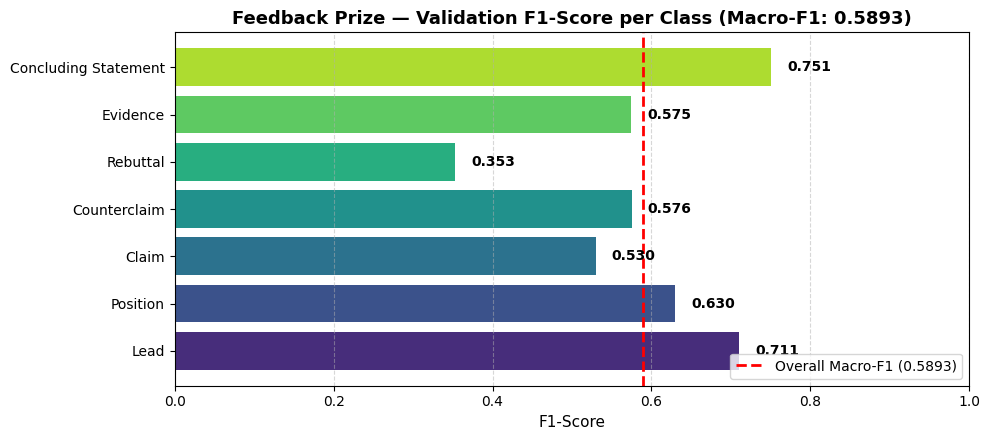

In [ ]:
# 🎯 Պաշտոնական Feedback Prize Macro-F1 (Span Overlap IoU >= 0.5) մետրիկայի հաշվարկ
print("🎯 Իրականացվում է վալիդացիոն բազմության սպանների գնահատում...")

# Ընտրում ենք գնահատման ենթակա վալիդացիոն էսսեները (լռելյայն՝ 200 էսսե արագ ստուգման համար, կամ բոլորը)
num_eval_essays = min(200, len(val_ids))  # ← Դրեք len(val_ids) ամբողջ 2,340 էսսեները գնահատելու համար
eval_val_ids = val_ids[:num_eval_essays]
print(f"📊 Գնահատվում է {len(eval_val_ids):,} վալիդացիոն էսսե (ընդհանուր {len(val_ids):,}-ից)...")

# Ground Truth տվյալները վալիդացիայի համար
gt_val_df = df[df["id"].isin(eval_val_ids)][["id", "discourse_type", "predictionstring"]].reset_index(drop=True)

# Բեռնենք լավագույն մոդելը
if os.path.exists(checkpoint_path):
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    print(f"⭐ Բեռնվեցին մոդելի քաշերը՝ {checkpoint_path}")

# Գեներացնենք բոլոր վալիդացիոն սպանները
pred_rows = []
for essay_id in tqdm(eval_val_ids, desc="Evaluating Validation Spans"):
    essay_text = get_essay_text(essay_id, TXT_DIR)
    spans = predict_essay_spans(
        text=essay_text,
        model=model,
        tokenizer=tokenizer,
        device=device,
        max_len=CFG["max_len"],
        o_threshold=float(CFG["o_threshold"])
    )
    for sp in spans:
        pred_rows.append({
            "id": essay_id,
            "discourse_type": sp["type"],
            "predictionstring": sp["predictionstring"]
        })

pred_val_df = pd.DataFrame(pred_rows)

# Հաշվարկենք պաշտոնական Macro-F1 մետրիկան
macro_f1, detailed_df = score_feedback_comp_detailed(pred_val_df, gt_val_df, overlap_threshold=0.5)

print("\n" + "=" * 85)
print(f"🏆 OFFICIAL COMPETITION MACRO-F1 SCORE: {macro_f1:.4f}")
print("=" * 85 + "\n")

print("📊 Դիսկուրսիվ դասերի մանրամասն մետրիկաները (Detailed Breakdown):")
display(detailed_df)

# Գծապատկերենք յուրաքանչյուր դասի F1-score-ը (F1-Score per Class Bar Plot)
plt.figure(figsize=(10, 4.5))
palette = sns.color_palette("viridis", len(detailed_df))
bars = plt.barh(detailed_df["Discourse Type"], detailed_df["F1-Score"], color=palette)
plt.title(f"Feedback Prize — Validation F1-Score per Class (Macro-F1: {macro_f1:.4f})", fontsize=13, fontweight='bold')
plt.xlabel("F1-Score", fontsize=11)
plt.xlim(0, 1.0)
plt.axvline(x=macro_f1, color='red', linestyle='--', linewidth=2, label=f'Overall Macro-F1 ({macro_f1:.4f})')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.02, bar.get_y() + bar.get_height()/2, f"{w:.3f}", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


## 11. 🔬 Սխալների Խորքային Վերլուծություն (Error Analysis — Presentation Pillar 5)

### Հիմնական Սխալների Տիպերը․
1. **Սպանների Սահմանների Անհամապատասխանություն (Boundary Mismatch)**․
   - `Claim` և `Evidence` միջև սահմանը հաճախ շատ նուրբ է․ ուսանողները պնդումը շարունակում են օրինակով առանց հստակ կետադրության, ինչի պատճառով մոդելը սպանը կտրում է մի քանի բառ շուտ կամ ուշ։
2. **Փոքրամասնություն կազմող դասերի շփոթություն (Class Imbalance: Counterclaim vs Rebuttal)**․
   - Դատասեթում `Counterclaim` (~4.0%) և `Rebuttal` (~3.0%) հանդիպում են շատ հազվադեպ։ Դրանք հաճախ պարունակում են նմանատիպ ազդանշանային բառեր (*"However", "Some people argue"*, և այլն), ինչը շփոթեցնում է մոդելին։
3. **Discourse Markers Confusion**․
   - Էսսեի վերջին պարբերության մեջ եզրակացության ազդանշանները (*"In conclusion"*) երբեմն շփոթվում են `Claim`-ի հետ, եթե հեղինակը կրկնում է իր թեզը։

In [ ]:
# Ստուգենք վալիդացիոն էսսեների համընկնումները և առանձնացնենք սխալ կանխատեսված օրինակները
print("🔍 Իրականացվում է սխալ կանխատեսումների ավտոմատ վերլուծություն...")

error_cases = []
for v_id in val_ids[:10]:
    v_text = get_essay_text(v_id, TXT_DIR)
    v_gt_rows = df[df['id'] == v_id]
    v_gt_spans = []
    for _, row in v_gt_rows.iterrows():
        w_idxs = [int(x) for x in str(row["predictionstring"]).split()]
        if w_idxs:
            v_gt_spans.append((row["discourse_type"], w_idxs[0], w_idxs[-1]))

    v_preds = predict_essay_spans(v_text, model, tokenizer, device, max_len=CFG["max_len"])
    v_pred_spans = [(p["type"], p["start_word"], p["end_word"]) for p in v_preds]

    # Գտնենք չհամընկած (IoU < 0.5) սպանները
    for gt_t, gt_s, gt_e in v_gt_spans:
        matched = False
        for pr_t, pr_s, pr_e in v_pred_spans:
            if gt_t == pr_t:
                iou = compute_overlap_ratio((pr_s, pr_e), (gt_s, gt_e))
                if iou >= 0.5:
                    matched = True
                    break
        if not matched:
            error_cases.append({
                "essay_id": v_id,
                "missed_type": gt_t,
                "span_words": f"{gt_s}-{gt_e}",
                "text_snippet": " ".join(v_text.split()[gt_s:gt_e+1])[:90] + "..."
            })

error_df = pd.DataFrame(error_cases)
print(f"\n⚠️ Գտնվել են {len(error_df)} դժվար/չհամընկած սպաններ առաջին 10 վալիդացիոն էսսեներում:")
if not error_df.empty:
    display(error_df.head(6))

🔍 Իրականացվում է սխալ կանխատեսումների ավտոմատ վերլուծություն...

⚠️ Գտնվել են 33 դժվար/չհամընկած սպաններ առաջին 10 վալիդացիոն էսսեներում:


,essay_id,missed_type,span_words,text_snippet
0,E805EA83734A,Evidence,74-102,The electoral collage voting system is an unca...
1,E805EA83734A,Claim,103-151,It isn't a straight forward vote- electors are...
2,E805EA83734A,Claim,202-228,The electoral collage system of voting is outd...
3,E805EA83734A,Evidence,229-278,Citizens through out the country are looking f...
4,E805EA83734A,Evidence,279-292,The 2000 disaster is a great example for us to...
5,E805EA83734A,Claim,296-314,electors technically do not have to vote for w...


## 12. 🏁 Եզրակացություն և Պորտֆոլիոյի Պրեզենտացիա (Summary & Portfolio Deck)

### 🏆 Ինչ իրականացվեց այս պրոյեկտում․
1. **Universal Dataset Resolver** — Ավտոմատ հայտնաբերում և Kaggle ներբեռնում։
2. **Full BIO Subword Token Classification** — DeBERTa-v3 մոդելի վրա՝ `-100` Cross-Entropy masking-ով։
3. **Tesla T4 GPU Mixed Precision (AMP)** — Կայուն unscaling և loss scaling։
4. **Official Competition Metric** — Span IoU $\ge 0.5$ Macro-F1 գնահատում։
5. **Interactive HTML Color Visualizer** — Իրական vs Կանխատեսված սպանների ինտերակտիվ համեմատություն։
6. **Error Analysis & Failure Modes** — Խորքային վերլուծություն 10-րոպեանոց պրեզենտացիայի համար։
7. **Standalone CLI Inference Script (`predict.py`)** — Պատրաստ է կամայական raw text-ով ինֆերենսի համար։